In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np # Library for math computations

from sklearn.impute import SimpleImputer # From the sklearn library to use for missing value imputation
from sklearn.pipeline import make_pipeline # This constructs our pipeline
from sklearn.linear_model import LinearRegression # Import Linear Regression function
from sklearn.tree import DecisionTreeRegressor # Decision Tree Regression


In [2]:
# Assign csv path to csv_path
csv_path = "/Users/jothamwambi/Projects/IUEA-Teaching-Resources/IUEA_Teaching_Plan/student_packages/CML3113_W08_student/engineering_data.csv"

# Read CSV file taking in the path in csv_path
raw_data = pd.read_csv(csv_path)

In [3]:
raw_data.head()

,record_id,equipment_id,load_pct,ambient_c,target
0,1,E1,59.15,31.71,14.001
1,2,E2,77.46,29.97,15.147
2,3,E3,69.60,19.87,13.005
3,4,E4,75.98,22.29,NaN
4,5,E5,57.62,23.40,12.554


In [4]:
raw_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91 entries, 0 to 90
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   record_id     91 non-null     int64  
 1   equipment_id  91 non-null     object 
 2   load_pct      91 non-null     float64
 3   ambient_c     90 non-null     float64
 4   target        90 non-null     float64
dtypes: float64(3), int64(1), object(1)
memory usage: 3.7+ KB


In [5]:
# Check for any missing values in our dataset
raw_data.isnull().sum()

record_id       0
equipment_id    0
load_pct        0
ambient_c       1
target          1
dtype: int64

In [6]:
missing_value_rows = raw_data[raw_data.isnull().any(axis=1)]
missing_value_rows

,record_id,equipment_id,load_pct,ambient_c,target
3,4,E4,75.98,22.29,NaN
13,14,E2,23.88,NaN,9.097


In [7]:
print(raw_data.duplicated().sum())

1


In [8]:
duplicated_row = raw_data[raw_data.duplicated()]
duplicated_row

,record_id,equipment_id,load_pct,ambient_c,target
90,1,E1,59.15,31.71,14.001


In [9]:
# Find invalid values in the dataset (in the load_pct column)
valid_values_load = raw_data["load_pct"].between(0, 100)

# Print values outside the valid range
print(raw_data.loc[~valid_values_load, "load_pct"])

# Print the value in the invalid cell
print(raw_data.loc[~valid_values_load, "load_pct"])

8   -5.0
Name: load_pct, dtype: float64
8   -5.0
Name: load_pct, dtype: float64


In [10]:
# Print the row with the invalid value
raw_data.loc[~valid_values_load, :]

,record_id,equipment_id,load_pct,ambient_c,target
8,9,E3,-5.0,21.57,13.908


**Cleaning**

In [11]:
# Create a copy of our data and store it in cleaned_data variable name

cleaned_data = raw_data.copy()

# Remove the rows with invalid values
cleaned_data = cleaned_data[valid_values_load]

# Check if the invalid values have been removed
cleaned_data[~cleaned_data["load_pct"].between(0, 100)]

,record_id,equipment_id,load_pct,ambient_c,target


In [12]:
# Remove the rows with missing values in target
cleaned_data = cleaned_data.dropna(subset=["target"])

# Check if the missing values have been removed
cleaned_data[cleaned_data["target"].isna()]


,record_id,equipment_id,load_pct,ambient_c,target


In [18]:
## Drop the duplicated rows by record_id column
cleaned_data = cleaned_data.drop_duplicates(subset=["record_id"])

# Check if the duplicated rows have been removed
print(cleaned_data.duplicated("record_id").sum())

0


In [21]:
cleaned_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 88 entries, 0 to 89
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   record_id     88 non-null     int64  
 1   equipment_id  88 non-null     object 
 2   load_pct      88 non-null     float64
 3   ambient_c     87 non-null     float64
 4   target        88 non-null     float64
dtypes: float64(3), int64(1), object(1)
memory usage: 4.1+ KB


In [23]:
cleaned_data.head()

,record_id,equipment_id,load_pct,ambient_c,target
0,1,E1,59.15,31.71,14.001
1,2,E2,77.46,29.97,15.147
2,3,E3,69.60,19.87,13.005
4,5,E5,57.62,23.40,12.554
5,6,E6,50.12,34.97,11.621


Text(0, 0.5, 'Frequency')

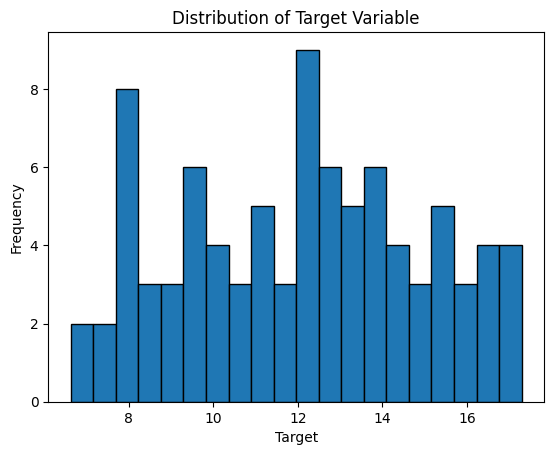

In [26]:
# Plot a histogram of the target variable
plt.hist(cleaned_data["target"], bins=20, edgecolor='black')
plt.title("Distribution of Target Variable")
plt.xlabel("Target")
plt.ylabel("Frequency")

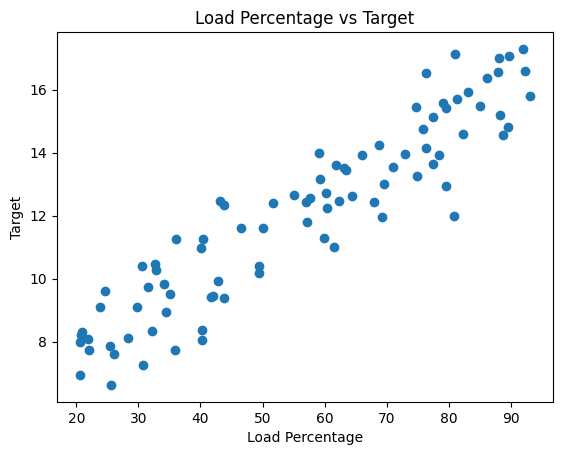

In [30]:
plt.scatter(cleaned_data["load_pct"], cleaned_data["target"])
plt.ylabel("Target")
plt.xlabel("Load Percentage")
plt.title("Load Percentage vs Target")

plt.show()

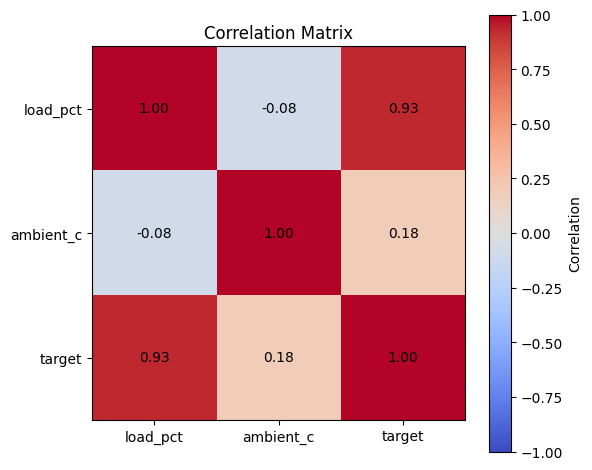

In [36]:
correlation_matrix = cleaned_data[['load_pct', 'ambient_c', 'target']].corr()

fig, ax = plt.subplots(figsize=(6, 5))
heatmap = ax.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_xticklabels(correlation_matrix.columns)
ax.set_yticks(range(len(correlation_matrix.index)))
ax.set_yticklabels(correlation_matrix.index)

for i in range(len(correlation_matrix.index)):
    for j in range(len(correlation_matrix.columns)):
        ax.text(j, i, f'{correlation_matrix.iloc[i, j]:.2f}',
                ha='center', va='center')

fig.colorbar(heatmap, ax=ax, label='Correlation')
ax.set_title('Correlation Matrix')
plt.tight_layout()
plt.show()